# Customer Feedback Intelligence System

## Day 11 — Business Analytics

**Project Domain:** Data Science, Machine Learning and NLP

### Objective

The objective of this task is to analyze customer feedback and generate useful business insights. This includes identifying top customer complaints, understanding the most appreciated product features, and comparing products based on ratings and customer reviews.


## 1. Load the Cleaned Dataset

In this section, we will load the cleaned customer feedback dataset. It contains product names, prices, ratings, reviews, and summaries. We will use this dataset to compare products and understand customer feedback for business decision-making.


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

file_path = r"C:\archive\Customer_Feedback_Cleaned.csv"

df = pd.read_csv(file_path, encoding="utf-8")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset Shape: (310789, 5)
Column Names: ['Product_name', 'Price', 'Rate', 'Review', 'Summary']


,Product_name,Price,Rate,Review,Summary
0,"Crompton 75 L Desert Air Cooler(White, Teal, A...",10499,5,simply awesome,really worth every single penny work like one ...
1,"Crompton 75 L Desert Air Cooler(White, Teal, A...",10499,4,worth money desert cooler live name,bought crompton ozone desert air cooler month ...
2,"Crompton 75 L Desert Air Cooler(White, Teal, A...",10499,5,worth every penny,great packaging seller important point transpo...
3,"Crompton 75 L Desert Air Cooler(White, Teal, A...",10499,5,fabulous,delivery delayed two day except everything qui...
4,"Crompton 75 L Desert Air Cooler(White, Teal, A...",10499,4,nice product,good cooler crompton height cooler ft inch col...


## 2. Load Aspect Sentiment Data

In this section, we load the aspect-level sentiment records generated during Day 10. These records will help us identify the product aspects with the most negative and positive customer feedback.


In [4]:

aspect_file_path = r"C:\archive\Aspect_Sentiment_Records.csv"

aspect_sentiment_df = pd.read_csv(
    aspect_file_path,
    encoding="utf-8"
)

print("Aspect sentiment data loaded successfully!")
print("Dataset Shape:", aspect_sentiment_df.shape)
print("Column Names:", aspect_sentiment_df.columns.tolist())

display(aspect_sentiment_df.head())

Aspect sentiment data loaded successfully!
Dataset Shape: (132191, 4)
Column Names: ['Aspect', 'Sentiment', 'Review', 'Rate']


,Aspect,Sentiment,Review,Rate
0,quality,Neutral,worth money desert cooler live name bought cro...,4
1,price,Positive,worth money desert cooler live name bought cro...,4
2,price,Neutral,worth every penny great packaging seller impor...,5
3,delivery,Neutral,fabulous delivery delayed two day except every...,5
4,quality,Neutral,super cant go wrong crompton brand punjab exce...,5


## 3. Top Complaints Analysis

In this section, we identify the product aspects with the highest number of negative customer feedback records. This analysis helps highlight areas where customers may be experiencing problems and where businesses may need to improve.


In [5]:


negative_records = aspect_sentiment_df[
    aspect_sentiment_df["Sentiment"] == "Negative"
]


top_complaints = (
    negative_records.groupby("Aspect")
    .size()
    .reset_index(name="Negative_Feedback_Count")
    .sort_values("Negative_Feedback_Count", ascending=False)
)

print("Top Complaints by Product Aspect:")
display(top_complaints)

Top Complaints by Product Aspect:


,Aspect,Negative_Feedback_Count
2,price,7501
3,quality,6649
4,sound,727
5,working,458
0,bass,238
1,delivery,173


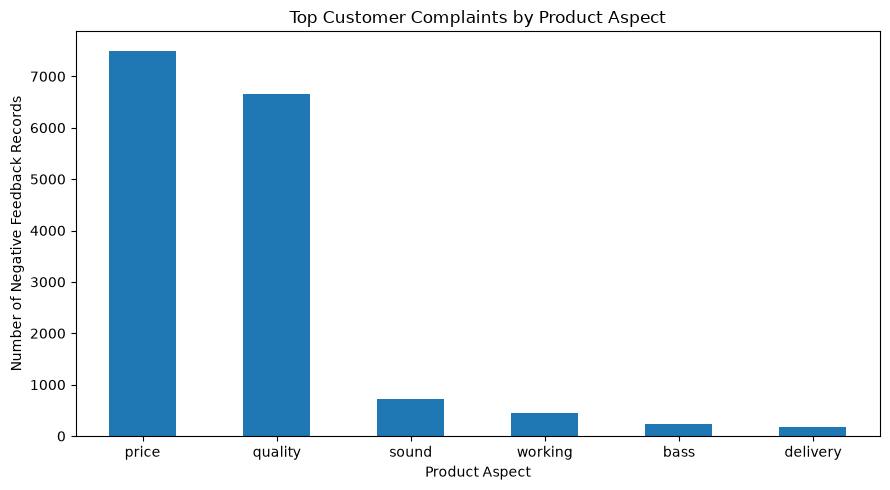

In [6]:

top_complaints.plot(
    x="Aspect",
    y="Negative_Feedback_Count",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Top Customer Complaints by Product Aspect")
plt.xlabel("Product Aspect")
plt.ylabel("Number of Negative Feedback Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

* Price received the highest number of negative feedback records, with 7,501 records.
* Quality ranked second, with 6,649 negative feedback records.
* Sound, Working, Bass, and Delivery had fewer negative feedback records.
* Price and Quality should be examined further to identify possible areas for improvement.

**Conclusion:** The analysis indicates that Price and Quality are the main aspects requiring attention in the available sentiment records. These results are based on rule-based sentiment classification and should be interpreted as estimates.


## 4. Most Appreciated Features

In this section, we identify the product aspects with the highest number of positive customer feedback records. This analysis helps businesses understand which product features customers appreciate and which strengths should be maintained.


In [9]:


positive_records = aspect_sentiment_df[
    aspect_sentiment_df["Sentiment"] == "Positive"
]


appreciated_features = (
    positive_records.groupby("Aspect")
    .size()
    .reset_index(name="Positive_Feedback_Count")
    .sort_values("Positive_Feedback_Count", ascending=False)
)

print("Most Appreciated Product Aspects:")
display(appreciated_features)

Most Appreciated Product Aspects:


,Aspect,Positive_Feedback_Count
3,quality,24224
2,price,15190
4,sound,9784
0,bass,4569
1,delivery,2743
5,working,2261


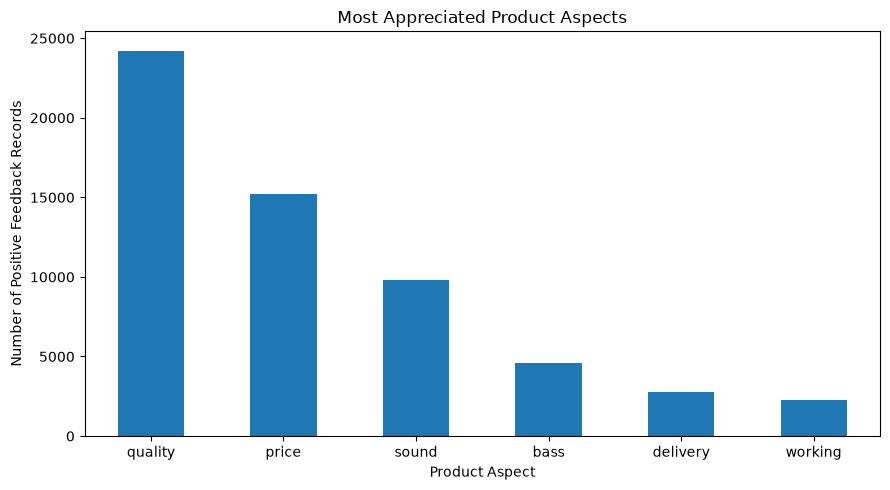

In [10]:

appreciated_features.plot(
    x="Aspect",
    y="Positive_Feedback_Count",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Most Appreciated Product Aspects")
plt.xlabel("Product Aspect")
plt.ylabel("Number of Positive Feedback Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

* Quality received the highest number of positive feedback records, with 24,224 records.
* Price ranked second, with 15,190 positive feedback records.
* Sound received 9,784 positive feedback records.
* Bass, Delivery, and Working received fewer positive feedback records than the other aspects.

**Conclusion:** Quality received the highest number of positive feedback records in this analysis. The business should maintain product quality and continue monitoring customer feedback. These results are based on rule-based sentiment classification and should be interpreted as estimates.


## 5. Product Comparison

In this section, we compare products using their average customer ratings, total number of reviews, and positive and negative feedback. This comparison helps identify products with better customer ratings and products that may require improvement.


In [11]:


df["Rate"] = pd.to_numeric(df["Rate"], errors="coerce")


comparison_df = df.dropna(
    subset=["Product_name", "Rate"]
).copy()


comparison_df["Overall_Sentiment"] = comparison_df["Rate"].apply(
    lambda rating: "Positive" if rating >= 4
    else "Neutral" if rating == 3
    else "Negative"
)


product_comparison = (
    comparison_df.groupby("Product_name")
    .agg(
        Average_Rating=("Rate", "mean"),
        Review_Count=("Rate", "count"),
        Positive_Reviews=(
            "Overall_Sentiment",
            lambda s: (s == "Positive").sum()
        ),
        Negative_Reviews=(
            "Overall_Sentiment",
            lambda s: (s == "Negative").sum()
        )
    )
    .reset_index()
)


product_comparison["Average_Rating"] = (
    product_comparison["Average_Rating"].round(2)
)


top_products = product_comparison.sort_values(
    "Review_Count", ascending=False
).head(10)

print("Top 10 Products by Review Count:")
display(top_products)

Top 10 Products by Review Count:


,Product_name,Average_Rating,Review_Count,Positive_Reviews,Negative_Reviews
1095,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4.30,6947,5730,569
121,Bumtum Baby Pull-Up Diaper Pants Combo Pack - ...,3.42,6900,3995,2260
342,Google Home Mini with Google Assistant Smart S...,4.11,6836,5249,977
580,Mi 5A 80 cm (32 inch) HD Ready LED Smart Andro...,4.25,6522,5405,622
538,MILTON Thermosteel Flip Lid 500 ml Flask(Pack ...,4.35,5935,5042,491
513,"Lakm Eyeconic Kajal Twin Pack(Deep Black, 0.7 g)",4.52,5071,4545,252
186,Crompton 88 L Desert Air Cooler with Honeycomb...,4.00,4481,3383,653
185,"Crompton 75 L Desert Air Cooler(White, Teal, A...",4.00,4481,3382,654
658,PHILIPS MMS8085B/94 Convertible 80 W Bluetooth...,4.24,4393,3594,486
659,PHILIPS SPA4040B/94 45 W Bluetooth Home Theatr...,4.01,4266,3193,712


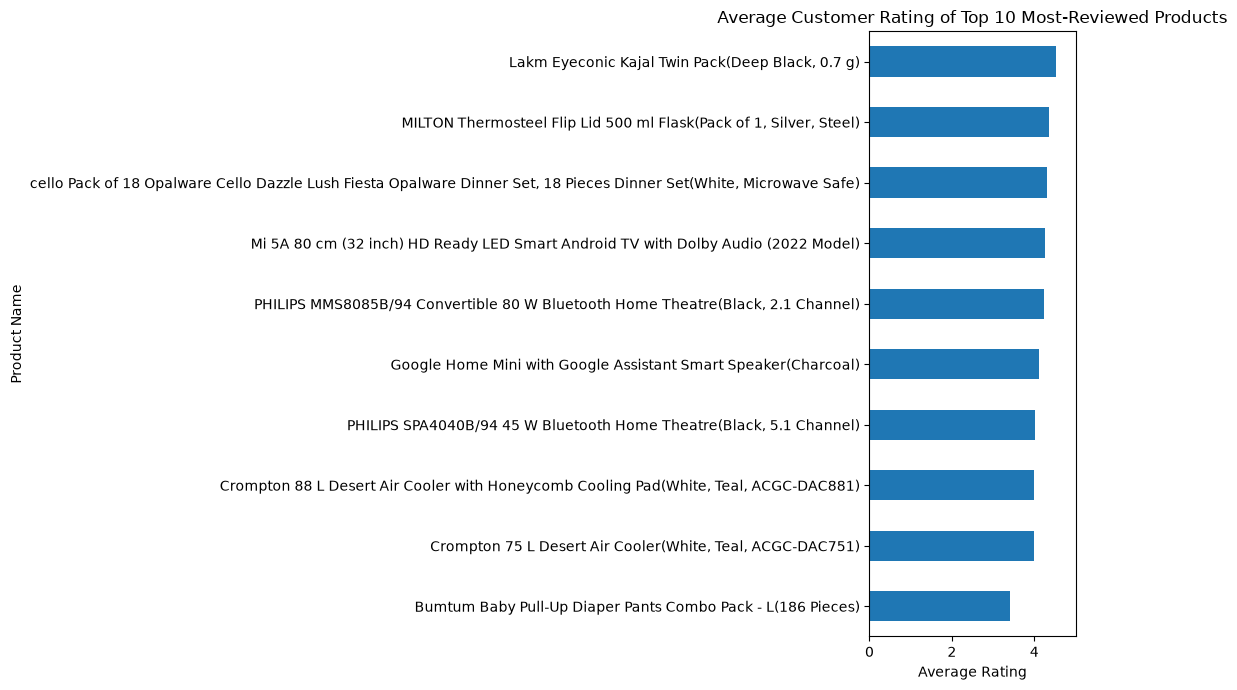

In [12]:

rating_chart_data = top_products.sort_values(
    "Average_Rating",
    ascending=True
)

rating_chart_data.plot(
    x="Product_name",
    y="Average_Rating",
    kind="barh",
    figsize=(11, 7),
    legend=False
)

plt.title("Average Customer Rating of Top 10 Most-Reviewed Products")
plt.xlabel("Average Rating")
plt.ylabel("Product Name")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### Key Findings — Product Comparison

* **Most Reviewed Product:** cello Pack of 18 Opalware Cello Dazzle Lush Fi... received 6,947 reviews.
* **Highest Average Rating:** Lakm Eyeconic Kajal received an average rating of 4.52 out of 5.
* **Lowest Average Rating:** Bumtum Baby Pull-Up Diaper Pants received an average rating of 3.42 out of 5 among the top 10 most-reviewed products.
* **Customer Feedback:** Product ratings vary across products, showing that review count and average rating provide different insights.
* **Business Insight:** Businesses can use review counts to understand feedback volume and average ratings to compare customer ratings. Products with lower average ratings can be investigated further to identify possible improvement areas.

**Conclusion:** Product comparison helps identify frequently reviewed products and products with higher or lower average ratings. These insights can support further investigation and business decision-making.


## 7. Overall Business Insights

### 1. Customer Complaints

The aspect-level sentiment analysis identified Price and Quality as the aspects with the highest negative feedback counts. These areas may require further investigation.

### 2. Appreciated Product Features

Quality received the highest number of positive feedback records, followed by Price and Sound. Businesses can use these findings to understand which aspects customers appreciate.

### 3. Product Rating Comparison

Among the top 10 most-reviewed products, Lakme Eyeconic Kajal had the highest average rating of 4.52, while Bumtum Baby Pull-Up Diaper Pants had the lowest average rating of 3.42.

### 4. Review Count and Average Rating

Review count indicates the volume of customer rating records, whereas average rating indicates the average score. Both measures are useful for comparing products.

### 5. Data Limitation

The dataset does not contain a separate Category column. Therefore, reliable category-wise analysis could not be performed.

### Business Conclusion

The analysis provides useful initial insights into customer complaints, appreciated product aspects, and product ratings. Businesses can use these findings to decide which products and aspects need further investigation. Aspect-level sentiment results are based on rule-based classification, so they should be validated before making important business decisions.


## 8. Final Conclusion

In this task, customer feedback data was analyzed to generate useful business insights. Negative feedback was examined to identify potential customer complaints, while positive feedback was analyzed to understand appreciated product aspects. Product comparison was performed using average ratings, review counts, and positive and negative rating counts.

The analysis identified Price and Quality as aspects with the highest negative feedback counts. Quality also received the highest number of positive feedback records. Among the top 10 most-reviewed products, Lakme Eyeconic Kajal had the highest average rating of 4.52 out of 5, while Bumtum Baby Pull-Up Diaper Pants had the lowest average rating of 3.42 out of 5.

This task helped demonstrate how customer ratings and feedback can support product comparison and business decision-making. However, aspect-level sentiment results were generated using rule-based classification and should be validated before practical use. Category-wise analysis was not possible because the dataset did not contain a separate Category column.

Overall, this task provided practical experience in analyzing customer feedback, identifying potential improvement areas, and presenting data-driven business insights.
